# **Skytrax Airline Reviews: порекомендует ли пассажир авиакомпанию**

# 0. Описание задачи

[Skytrax](https://www.airlinequality.com/) — сайт, на котором пассажиры оставляют отзывы об авиакомпаниях. В отзыве пассажир ставит общую оценку от 1 до 10, оценивает отдельные стороны полёта (кресло, обслуживание, еду, развлечения, наземное обслуживание, соотношение цены и качества) по шкале от 1 до 5, пишет текст и отвечает на вопрос, рекомендует ли он эту авиакомпанию. Датасет взят с Kaggle: [Skytrax Airline Reviews](https://www.kaggle.com/datasets/efehandanisman/skytrax-airline-reviews), файл `capstone_airline_reviews3.xlsx`. Каждая непустая строка — один отзыв.

**Что предсказываем.** Целевой признак `recommended`: `yes` — пассажир рекомендует авиакомпанию, `no` — не рекомендует.

**Тип задачи** — бинарная классификация.

**Физический смысл.** Авиакомпании и агрегаторы отзывов собирают оценки по отдельным аспектам полёта. Хочется понять, *какие* аспекты сильнее всего определяют, станет ли клиент рекомендовать компанию, и уметь восстанавливать итоговое решение по оценкам (в датасете ответ о рекомендации пропущен у ~1 400 отзывов).

**Два сценария.**
1. *Основной* — по оценкам аспектов полёта и сведениям об отзыве определить итоговую рекомендацию. Оценки ставятся в **том же отзыве, после поездки**. Поэтому модель объясняет, как мнение пассажира складывается из оценок отдельных сторон полёта, но **не прогнозирует рекомендацию заранее, до полёта**.
2. *Дополнительный* (раздел 10) — только сведения, известные до полёта: авиакомпания, класс, тип путешественника, маршрут, год. Он показывает, насколько предсказуема рекомендация без оценок пассажира.

Общая оценка `overall` и текст отзыва — фактически другая форма того же ответа (раздел 3), поэтому в признаки не входят ни в одном сценарии.

## Описание признаков

| Признак | Описание | Тип |
|---|---|---|
| `airline` | авиакомпания | категориальный (81 значение) |
| `overall` | общая оценка полёта, 1–10 | порядковый |
| `author` | имя автора отзыва | идентификатор |
| `review_date` | дата публикации отзыва (строка вида «8th May 2019») | дата |
| `customer_review` | текст отзыва | текст |
| `aircraft` | тип самолёта | категориальный (тысячи значений) |
| `traveller_type` | тип путешественника: Solo/Couple/Family Leisure, Business | категориальный |
| `cabin` | класс обслуживания: Economy, Premium Economy, Business, First | категориальный |
| `route` | маршрут (строка вида «London to Izmir via Istanbul») | текст / категориальный |
| `date_flown` | месяц полёта | дата |
| `seat_comfort` | удобство кресла, 1–5 | порядковый |
| `cabin_service` | обслуживание в салоне, 1–5 | порядковый |
| `food_bev` | еда и напитки, 1–5 | порядковый |
| `entertainment` | развлечения на борту, 1–5 | порядковый |
| `ground_service` | наземное обслуживание, 1–5 | порядковый |
| `value_for_money` | соотношение цены и качества, 1–5 | порядковый |
| `recommended` | **целевой**: рекомендует ли пассажир (`yes`/`no`) | бинарный |

## Как устроена работа

Разделы пронумерованы по пунктам требований преподавателя (0–13); таблица соответствия — в конце ноутбука. Чтобы не было утечки данных:
- до разбиения выполняются только технические операции над отдельными строками: удаление пустых строк, дубликатов и отзывов без целевого признака, разбор дат и текстовых полей;
- разведочный анализ, выбросы и пропуски анализируются **на обучающей выборке**;
- заполнение пропусков, логарифмирование, кодирование и масштабирование выполняются внутри `Pipeline`/`ColumnTransformer` и обучаются только на обучающей выборке;
- гиперпараметры и лучшая модель выбираются **кросс-валидацией на обучающей выборке**; тестовая выборка используется только для итоговой оценки.

# 1. Чтение данных

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, classification_report)

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

RANDOM_STATE = 42

In [2]:
# Ищем файл с данными: в папке data/ или в корне проекта
DATA_FILE = 'capstone_airline_reviews3.xlsx'
candidates = [Path('../data'), Path('..'), Path('data'), Path('.')]
data_path = next((p / DATA_FILE for p in candidates if (p / DATA_FILE).exists()), None)
if data_path is None:
    raise FileNotFoundError(f'Положите {DATA_FILE} в папку data/ в корне проекта')
print('Файл:', data_path)

raw = pd.read_excel(data_path)   # чтение xlsx занимает около минуты
print('Размер исходного файла:', raw.shape)
raw.head(6)

Файл: ../capstone_airline_reviews3.xlsx


Размер исходного файла: (131895, 17)


,airline,overall,author,review_date,customer_review,aircraft,traveller_type,cabin,route,date_flown,seat_comfort,cabin_service,food_bev,entertainment,ground_service,value_for_money,recommended
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Turkish Airlines,7.0,Christopher Hackley,8th May 2019,âœ… Trip Verified | London to Izmir via Istanb...,NaN,Business,Economy Class,London to Izmir via Istanbul,2019-05-01 00:00:00,4.0,5.0,4.0,4.0,2.0,4.0,yes
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Turkish Airlines,2.0,Adriana Pisoi,7th May 2019,âœ… Trip Verified | Istanbul to Bucharest. We ...,NaN,Family Leisure,Economy Class,Istanbul to Bucharest,2019-05-01 00:00:00,4.0,1.0,1.0,1.0,1.0,1.0,no
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Turkish Airlines,3.0,M Galerko,7th May 2019,âœ… Trip Verified | Rome to Prishtina via Ista...,NaN,Business,Economy Class,Rome to Prishtina via Istanbul,2019-05-01 00:00:00,1.0,4.0,1.0,3.0,1.0,2.0,no


## Пустые строки и дубликаты

Уже по первым строкам видно, что **каждая вторая строка файла полностью пустая**. Это артефакт выгрузки, а не объекты, поэтому такие строки удаляем.

In [3]:
empty_rows = raw.isna().all(axis=1)
print(f'Полностью пустых строк: {empty_rows.sum()} из {len(raw)}')
data = raw[~empty_rows].reset_index(drop=True)
print('После удаления пустых строк:', data.shape)

full_dups = data.duplicated()
print('Полных дубликатов строк:', full_dups.sum())
data = data[~full_dups]

# Тот же автор с тем же текстом (могут отличаться, например, пропуском в одном из полей)
text_dups = data.duplicated(['author', 'customer_review'])
print('Дополнительно дублей по (автор, текст):', text_dups.sum())
data = data[~text_dups].reset_index(drop=True)
print('После удаления дубликатов:', data.shape)

Полностью пустых строк: 65948 из 131895
После удаления пустых строк: (65947, 17)


Полных дубликатов строк: 4764


Дополнительно дублей по (автор, текст): 6
После удаления дубликатов: (61177, 17)


Дубликаты удаляем **до** разбиения: иначе копия одного и того же отзыва могла бы попасть и в обучающую, и в тестовую выборку, и оценка качества была бы завышена.

## Типы столбцов

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 61177 entries, 0 to 61176
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   airline          61177 non-null  str    
 1   overall          59395 non-null  float64
 2   author           61177 non-null  str    
 3   review_date      61177 non-null  str    
 4   customer_review  61177 non-null  str    
 5   aircraft         18486 non-null  object 
 6   traveller_type   37536 non-null  str    
 7   cabin            58700 non-null  str    
 8   route            37509 non-null  str    
 9   date_flown       37430 non-null  object 
 10  seat_comfort     56205 non-null  float64
 11  cabin_service    56234 non-null  float64
 12  food_bev         48335 non-null  float64
 13  entertainment    40224 non-null  float64
 14  ground_service   37165 non-null  float64
 15  value_for_money  59321 non-null  float64
 16  recommended      59755 non-null  str    
dtypes: float64(7), object(2

In [5]:
rating_cols = ['seat_comfort', 'cabin_service', 'food_bev',
               'entertainment', 'ground_service', 'value_for_money']
for col in ['overall'] + rating_cols:
    print(f'{col:16s}', sorted(data[col].dropna().unique().astype(int).tolist()))
print()
print('Типы значений date_flown:')
print(data['date_flown'].map(lambda v: type(v).__name__).value_counts())

overall          [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
seat_comfort     [1, 2, 3, 4, 5]
cabin_service    [1, 2, 3, 4, 5]
food_bev         [1, 2, 3, 4, 5]
entertainment    [1, 2, 3, 4, 5]
ground_service   [1, 2, 3, 4, 5]
value_for_money  [1, 2, 3, 4, 5]

Типы значений date_flown:
date_flown
str         34792
float       23747
datetime     2638
Name: count, dtype: int64


Все оценки (`overall` и шесть аспектов) прочитаны как числа с плавающей точкой (`float64` из-за пропусков). Текстовых значений среди них нет, все значения лежат в пределах шкал: `overall` 1–10, аспекты 1–5. Остальные столбцы — строки. В `date_flown` смешаны объекты `datetime` и строки вида «April 2019».

## Целевой признак

In [6]:
print('Пропусков в recommended:', data['recommended'].isna().sum())
data = data.dropna(subset=['recommended']).reset_index(drop=True)
print('Осталось отзывов:', len(data))
data['recommended'].value_counts()

Пропусков в recommended: 1422
Осталось отзывов: 59755


recommended
no     31266
yes    28489
Name: count, dtype: int64

Отзывы без ответа о рекомендации для обучения непригодны, поэтому удаляем их. Подробно распределение классов разберём в разделе 3, уже на обучающей выборке.

## Признаки из дат, текста и маршрута

Эти преобразования работают с каждой строкой независимо и не используют статистик по выборке. Поэтому их можно выполнить до разбиения без риска утечки.

In [7]:
def parse_review_date(s):
    # '8th May 2019' -> 2019-05-08
    s = s.str.replace(r'(\d+)(st|nd|rd|th)', r'\1', regex=True)
    return pd.to_datetime(s, format='%d %B %Y', errors='coerce')


def verification_status(text):
    head = text.str[:40]
    return np.select([head.str.contains('Not Verified'), head.str.contains('Verified')],
                     ['not_verified', 'verified'], default='not_stated')


def route_type(route):
    return np.select([route.isna(), route.str.contains(' via ', na=False)],
                     ['unknown', 'transfer'], default='direct')


review_dt = parse_review_date(data['review_date'])
print('Не разобрано дат отзыва:', review_dt.isna().sum())
data['review_year'] = review_dt.dt.year
data['verified'] = verification_status(data['customer_review'])
data['review_words'] = data['customer_review'].str.split().str.len()
data['route_type'] = route_type(data['route'])
data['target'] = (data['recommended'] == 'yes').astype(int)

data[['review_date', 'review_year', 'verified', 'review_words', 'route', 'route_type']].head()

Не разобрано дат отзыва: 0


,review_date,review_year,verified,review_words,route,route_type
0,8th May 2019,2019,verified,208,London to Izmir via Istanbul,transfer
1,7th May 2019,2019,verified,89,Istanbul to Bucharest,direct
2,7th May 2019,2019,verified,301,Rome to Prishtina via Istanbul,transfer
3,6th May 2019,2019,verified,162,Washington Dulles to Karachi,direct
4,6th May 2019,2019,verified,77,Mumbai to Dublin via Istanbul,transfer


- `review_year` — год публикации отзыва. Дата отзыва разбирается без ошибок. `date_flown` пропущена примерно в 40% строк и почти повторяет год отзыва, поэтому её не используем;
- `verified` — отметка Skytrax в начале текста: «Trip Verified» / «Verified Review» (поездка подтверждена), «Not Verified» или отметки нет (старые отзывы). Это метаданные, а не мнение пассажира;
- `review_words` — длина отзыва в словах;
- `route_type` — прямой рейс, с пересадкой («via») или маршрут не указан. Сам маршрут не используем: у него более 24 тысяч уникальных значений, модель бы на них переобучилась.

**Не используем:**
- `overall` — почти тот же ответ, что и целевой признак (раздел 3);
- текст `customer_review` — в нём обычно прямо написан вывод («I would not recommend…»); берём только его длину и отметку верификации;
- `author` — идентификатор;
- `aircraft` — 70% пропусков и тысячи уникальных значений;
- `route`, `date_flown` — см. выше.

# 2. Разбиение на обучающую и тестовую выборки

In [8]:
rating_features = rating_cols
numeric_features = ['review_year']
log_features = ['review_words']
categorical_features = ['airline', 'cabin', 'traveller_type', 'verified', 'route_type']
features = rating_features + numeric_features + log_features + categorical_features

assert 'recommended' not in features and 'target' not in features and 'overall' not in features

X = data[features]
y = data['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('train:', X_train.shape, ' test:', X_test.shape)
print('Доля yes: train = %.3f, test = %.3f' % (y_train.mean(), y_test.mean()))

# Полные строки обучающей выборки (вместе с overall, текстом и т.п.) — для разведочного анализа
train_df = data.loc[X_train.index]

train: (47804, 13)  test: (11951, 13)
Доля yes: train = 0.477, test = 0.477


20% отзывов откладываем в тестовую выборку со стратификацией по классу (`random_state = 42`). Все модели сравниваются на этом одном разбиении. Разведочный анализ дальше проводится только по `train_df`, то есть по обучающим строкам.

# 3. Визуализация и основные характеристики

## Основные характеристики числовых признаков

In [9]:
num_cols = ['overall'] + rating_cols + ['review_year', 'review_words']
train_df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
overall,46425.0,5.17,3.49,1.0,1.0,5.0,9.0,10.0
seat_comfort,44917.0,2.96,1.43,1.0,2.0,3.0,4.0,5.0
cabin_service,44947.0,3.20,1.57,1.0,2.0,3.0,5.0,5.0
food_bev,38666.0,2.93,1.48,1.0,1.0,3.0,4.0,5.0
entertainment,32167.0,2.89,1.50,1.0,1.0,3.0,4.0,5.0
ground_service,29720.0,2.67,1.61,1.0,1.0,3.0,4.0,5.0
value_for_money,47461.0,2.95,1.59,1.0,1.0,3.0,4.0,5.0
review_year,47804.0,2015.59,2.13,2002.0,2014.0,2016.0,2017.0,2019.0
review_words,47804.0,138.62,94.22,12.0,74.0,113.0,173.0,1003.0


- Средние оценки аспектов около 2.7–3.2 при медиане 3, разброс (стандартное отклонение) большой, около 1.4–1.6 на шкале 1–5. Пассажиры часто ставят крайние оценки.
- Наименьшее среднее у `ground_service`, наибольшее у `cabin_service`.
- `overall` в среднем ~5.2, но первый квартиль равен 1, а третий 9: распределение «двугорбое».
- Длина отзыва от ~12 до ~1000 слов, среднее заметно больше медианы, то есть хвост длинный, справа.

## Целевой признак

             число   доля
recommended              
no           25013  0.523
yes          22791  0.477


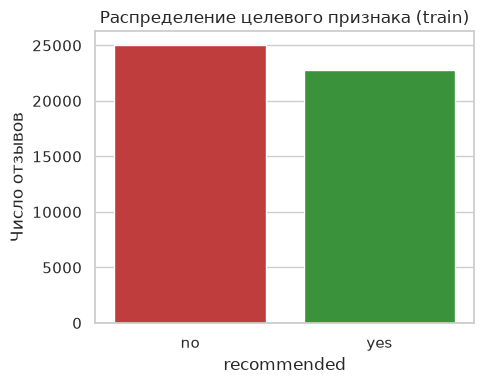

In [10]:
target_counts = train_df['recommended'].value_counts()
print(pd.DataFrame({'число': target_counts, 'доля': (target_counts / len(train_df)).round(3)}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=train_df, x='recommended', order=['no', 'yes'], ax=ax,
              hue='recommended', palette={'no': 'tab:red', 'yes': 'tab:green'}, legend=False)
ax.set_title('Распределение целевого признака (train)')
ax.set_xlabel('recommended')
ax.set_ylabel('Число отзывов')
plt.tight_layout()
plt.show()

Классы почти сбалансированы: `no` немного больше, чем `yes`. Константный классификатор «всегда `no`» даёт точность около 0.52; это нижняя граница, с которой будем сравнивать модели.

## Утечка целевого признака: `overall`

overall,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0
recommended,,,,,,,,,,
no,12564,4211,2815,1645,1501,586,204,52,28,31
yes,43,59,109,226,786,1309,3087,5182,5737,6250


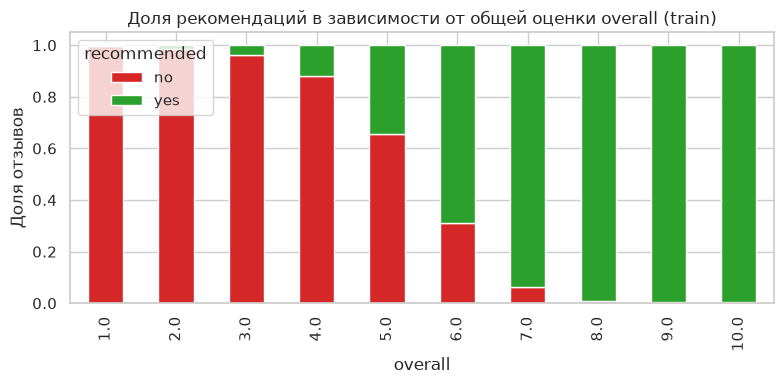

Правило 'overall >= 6 -> yes' угадывает 0.954 ответов


In [11]:
ct = pd.crosstab(train_df['overall'], train_df['recommended'])
display(ct.T)

ax = (ct.div(ct.sum(axis=1), axis=0)
        .plot.bar(stacked=True, figsize=(8, 4), color=['tab:red', 'tab:green']))
ax.set_title('Доля рекомендаций в зависимости от общей оценки overall (train)')
ax.set_xlabel('overall')
ax.set_ylabel('Доля отзывов')
ax.legend(title='recommended', loc='upper left')
plt.tight_layout()
plt.show()

known = train_df.dropna(subset=['overall'])
rule = np.where(known['overall'] >= 6, 'yes', 'no')
print(f"Правило 'overall >= 6 -> yes' угадывает {np.mean(rule == known['recommended']):.3f} ответов")

Общая оценка `overall` и рекомендация — фактически один и тот же ответ пассажира в двух формах: одно пороговое правило угадывает около 95% ответов. С `overall` среди признаков задача стала бы тривиальной, а модель бесполезной (если `overall` известна, рекомендацию можно не предсказывать). Поэтому `overall` **исключён из признаков**.

Оценки аспектов тоже ставятся в том же отзыве. Они не повторяют ответ напрямую, но сильно с ним связаны. Это и есть ограничение основного сценария (раздел 0).

## Распределения оценок по аспектам

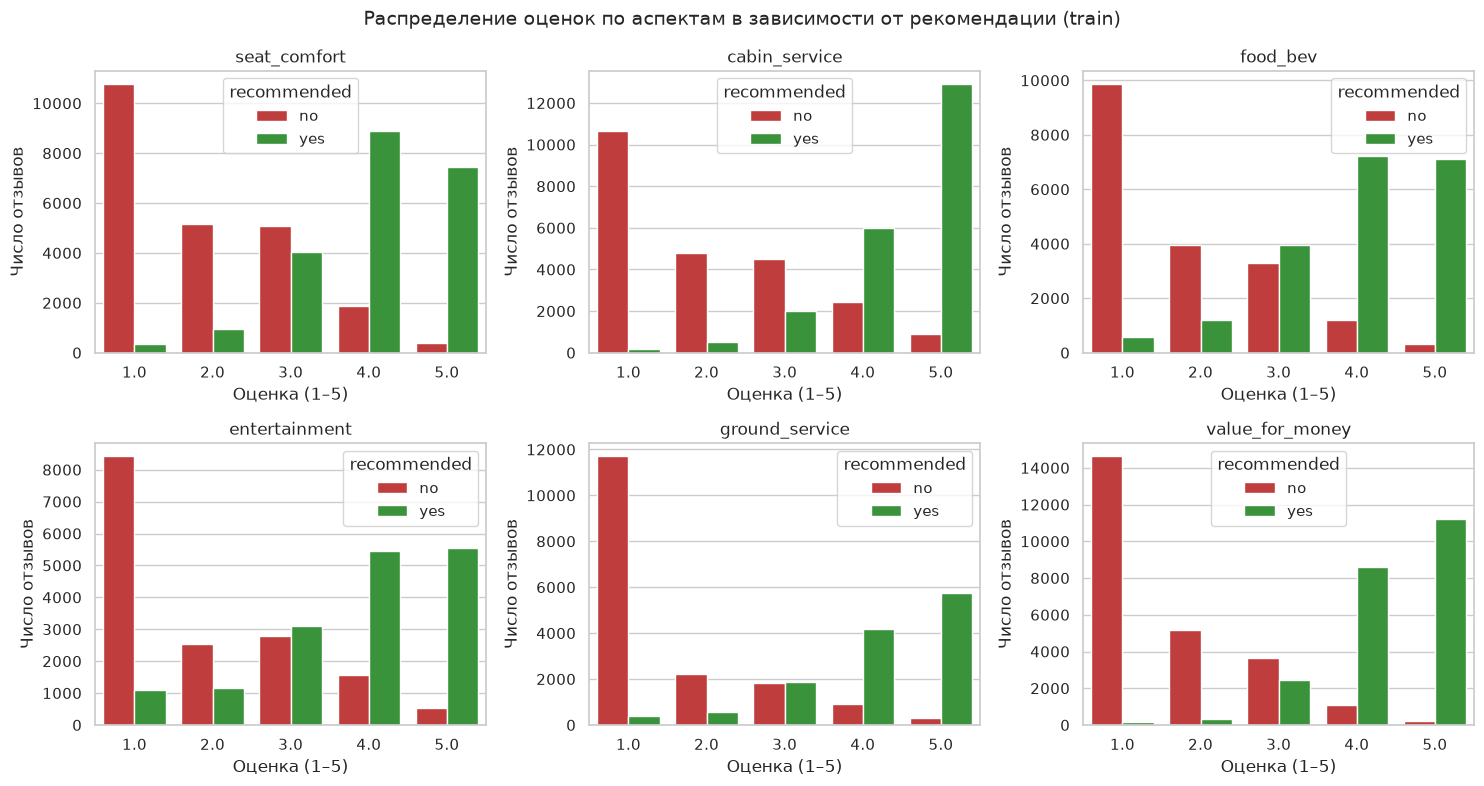

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), rating_cols):
    sns.countplot(data=train_df, x=col, hue='recommended', hue_order=['no', 'yes'],
                  palette={'no': 'tab:red', 'yes': 'tab:green'}, ax=ax)
    ax.set_title(f'{col}')
    ax.set_xlabel('Оценка (1–5)')
    ax.set_ylabel('Число отзывов')
fig.suptitle('Распределение оценок по аспектам в зависимости от рекомендации (train)', fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
stats_by_class = train_df.groupby('recommended')[rating_cols].agg(['mean', 'std']).T.unstack()
stats_by_class.columns = [f'{c} ({s})' for s, c in stats_by_class.columns]
stats_by_class['разница средних'] = stats_by_class['mean (yes)'] - stats_by_class['mean (no)']
stats_by_class.sort_values('разница средних', ascending=False).round(2)

,mean (no),std (no),mean (yes),std (yes),разница средних
value_for_money,1.67,0.94,4.34,0.78,2.67
ground_service,1.58,1.00,4.13,1.01,2.54
cabin_service,2.06,1.19,4.43,0.83,2.37
food_bev,1.82,1.04,3.95,1.02,2.13
seat_comfort,1.97,1.07,4.02,0.92,2.05
entertainment,1.94,1.18,3.80,1.18,1.86


Распределения оценок **бимодальные**: чаще всего ставят крайние значения 1 или 5. Классы разделяются очень хорошо: у рекомендующих все оценки в среднем на 1.9–2.7 балла выше. Сильнее всего различается `value_for_money`, слабее всего `entertainment`.

## Категориальные признаки: частоты

In [14]:
for col in ['cabin', 'traveller_type', 'verified', 'route_type']:
    vc = train_df[col].fillna('нет данных').value_counts()
    display(pd.DataFrame({'число': vc, 'доля, %': (vc / len(train_df) * 100).round(1),
                          'доля yes': train_df.groupby(train_df[col].fillna('нет данных'))['target']
                                               .mean().reindex(vc.index).round(3)})
            .rename_axis(col))

,число,"доля, %",доля yes
cabin,,,
Economy Class,36151,75.6,0.436
Business Class,7684,16.1,0.665
Premium Economy,1893,4.0,0.500
First Class,1232,2.6,0.623
нет данных,844,1.8,0.267


,число,"доля, %",доля yes
traveller_type,,,
нет данных,17789,37.2,0.562
Solo Leisure,11208,23.4,0.489
Couple Leisure,7722,16.2,0.378
Family Leisure,5711,11.9,0.392
Business,5374,11.2,0.402


,число,"доля, %",доля yes
verified,,,
not_stated,26879,56.2,0.543
verified,19543,40.9,0.404
not_verified,1382,2.9,0.221


,число,"доля, %",доля yes
route_type,,,
direct,20504,42.9,0.425
unknown,17809,37.3,0.561
transfer,9491,19.9,0.431


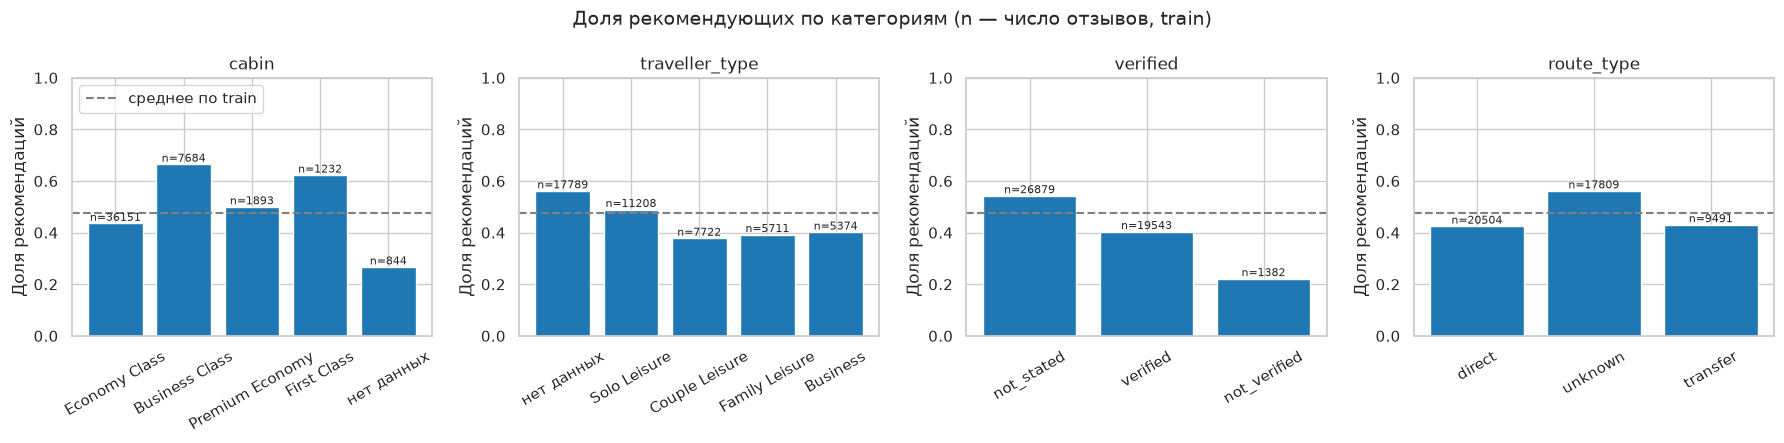

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, ['cabin', 'traveller_type', 'verified', 'route_type']):
    share = (train_df.assign(**{col: train_df[col].fillna('нет данных')})
                     .groupby(col)['target'].agg(['mean', 'size']).sort_values('size', ascending=False))
    ax.bar(share.index.astype(str), share['mean'], color='tab:blue')
    for i, (m, n) in enumerate(zip(share['mean'], share['size'])):
        ax.text(i, m + 0.01, f'n={n}', ha='center', fontsize=8)
    ax.axhline(train_df['target'].mean(), color='gray', ls='--', label='среднее по train')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('Доля рекомендаций')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=30)
axes[0].legend(loc='upper left')
fig.suptitle('Доля рекомендующих по категориям (n — число отзывов, train)', fontsize=14)
plt.tight_layout()
plt.show()

- **Класс обслуживания**: почти 3/4 отзывов про эконом. В бизнес- и первом классе рекомендуют около 63–67% пассажиров, в экономе около 44%.
- **Тип путешественника**: в новых отзывах доля рекомендаций около 38–49% (выше всего у Solo Leisure), а в старых отзывах без этого поля около 56%.
- **Верификация**: отзывы «Not Verified» положительны лишь в ~22% случаев, подтверждённые в ~41%, без отметки (в основном старые) в ~54%. Отметка верификации появилась на сайте позже, поэтому признак частично отражает время публикации.

## Авиакомпании

Число авиакомпаний: 81
Отзывов на авиакомпанию (train): min = 41 , медиана = 451.0 , max = 2243


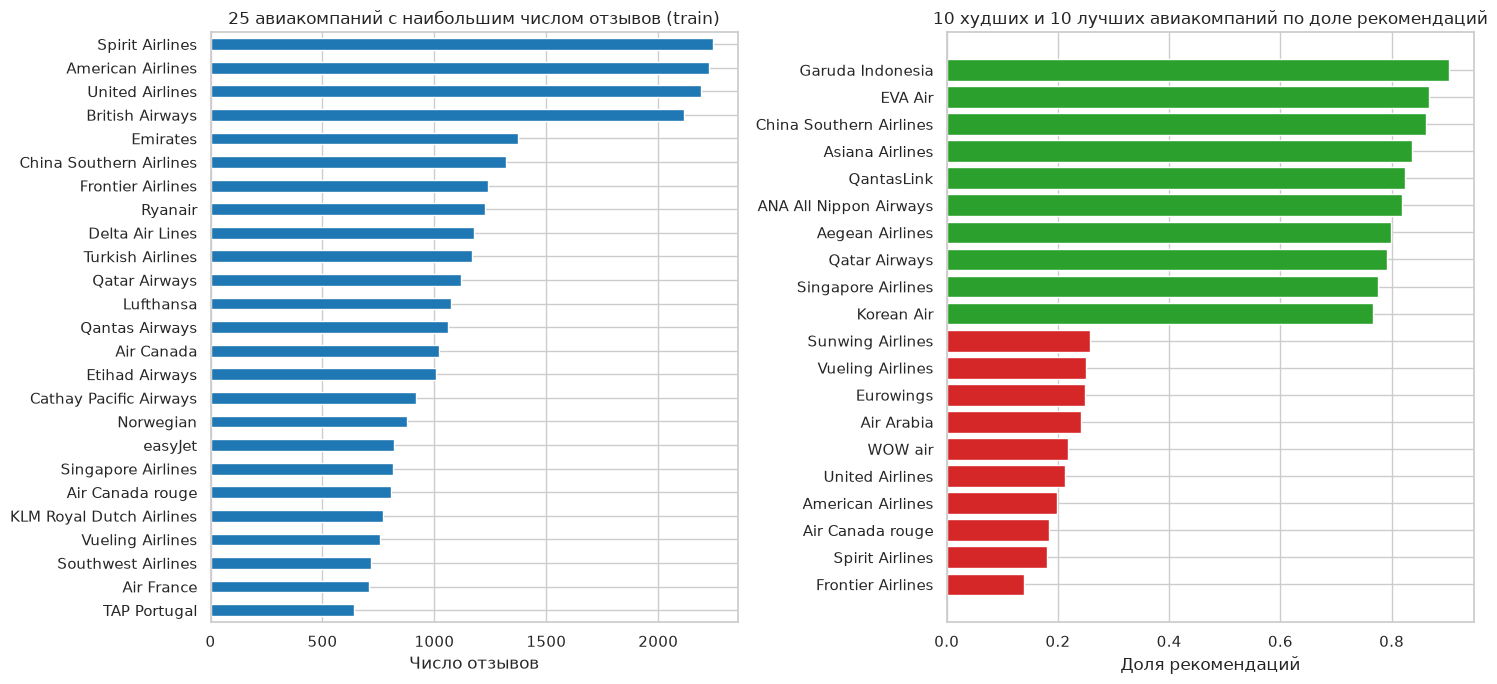

In [16]:
airline_stats = train_df.groupby('airline')['target'].agg(['mean', 'size'])
print('Число авиакомпаний:', len(airline_stats))
print('Отзывов на авиакомпанию (train): min =', airline_stats['size'].min(),
      ', медиана =', airline_stats['size'].median(), ', max =', airline_stats['size'].max())

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
top = airline_stats.sort_values('size', ascending=False).head(25)
top['size'].sort_values().plot.barh(ax=axes[0], color='tab:blue')
axes[0].set_title('25 авиакомпаний с наибольшим числом отзывов (train)')
axes[0].set_xlabel('Число отзывов')
axes[0].set_ylabel('')

extremes = pd.concat([airline_stats.sort_values('mean').head(10),
                      airline_stats.sort_values('mean').tail(10)])
colors = ['tab:red'] * 10 + ['tab:green'] * 10
axes[1].barh(extremes.index, extremes['mean'], color=colors)
axes[1].set_title('10 худших и 10 лучших авиакомпаний по доле рекомендаций')
axes[1].set_xlabel('Доля рекомендаций')
plt.tight_layout()
plt.show()

Авиакомпания — сильный признак: доля рекомендаций меняется от ~0.14–0.2 (американские лоукостеры и магистральные перевозчики США: Frontier, Spirit, American, United) до ~0.85–0.9 (EVA Air, China Southern, Garuda Indonesia). У каждой авиакомпании в обучающей выборке несколько десятков отзывов или больше, поэтому подойдёт one-hot кодирование.

## Время публикации

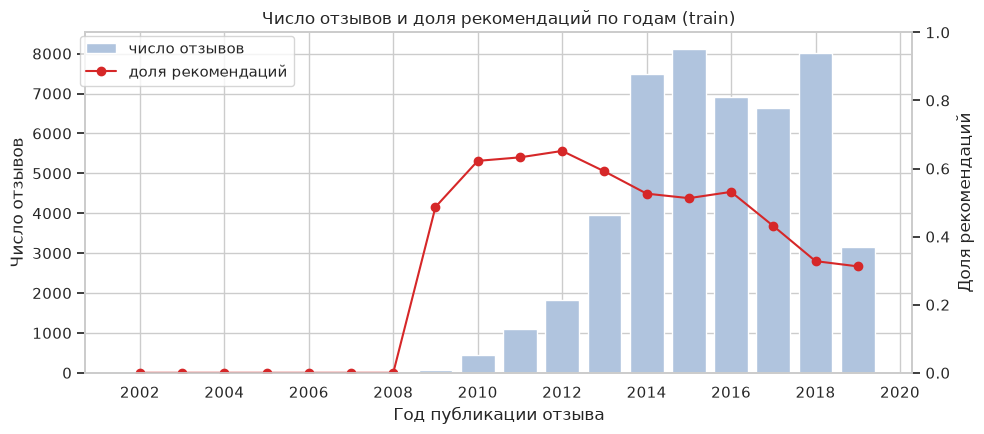

In [17]:
by_year = train_df.groupby('review_year')['target'].agg(['mean', 'size'])
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(by_year.index, by_year['size'], color='lightsteelblue', label='число отзывов')
ax1.set_xlabel('Год публикации отзыва')
ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax1.set_ylabel('Число отзывов')
ax2 = ax1.twinx()
ax2.plot(by_year.index, by_year['mean'], color='tab:red', marker='o', label='доля рекомендаций')
ax2.set_ylabel('Доля рекомендаций')
ax2.set_ylim(0, 1)
ax2.grid(False)
fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.92))
ax1.set_title('Число отзывов и доля рекомендаций по годам (train)')
plt.tight_layout()
plt.show()

Основная масса отзывов относится к 2013–2019 годам. До 2009 года отзывов единицы (менее сотни), и все они отрицательные. В 2010–2012 годах доля рекомендаций около 0.6–0.65, затем она снижается до ~0.3 в 2019 году. Отчасти это может быть связано со сменой состава авиакомпаний на сайте, а не только с ухудшением сервиса.

## Длина отзыва

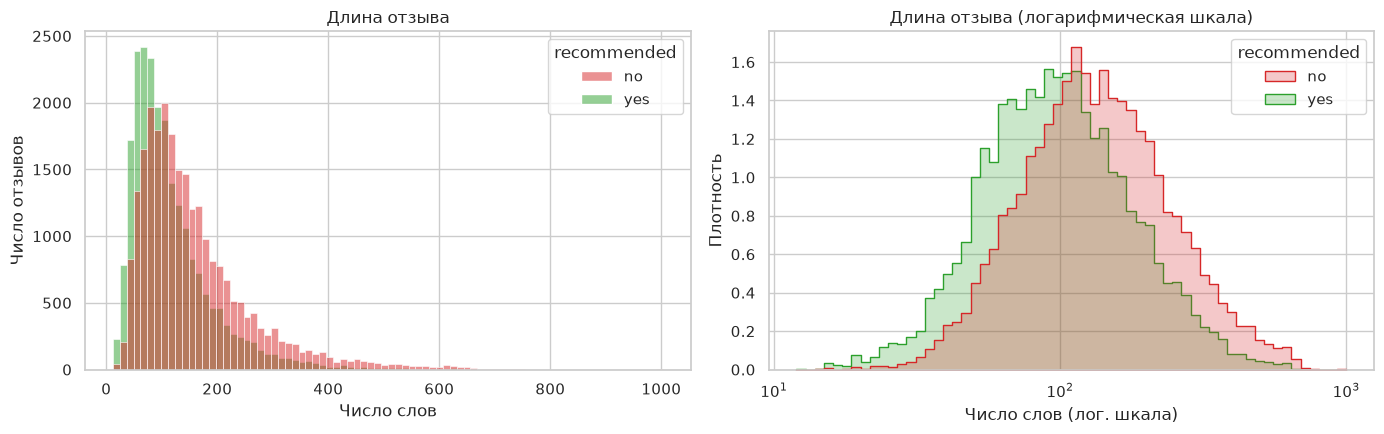

,count,mean,std,min,25%,50%,75%,max
recommended,,,,,,,,
no,25013.0,158.7,103.0,14.0,88.0,131.0,197.0,1003.0
yes,22791.0,116.6,77.8,12.0,64.0,96.0,144.0,665.0


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=train_df, x='review_words', hue='recommended', hue_order=['no', 'yes'],
             palette={'no': 'tab:red', 'yes': 'tab:green'}, bins=80, ax=axes[0])
axes[0].set_title('Длина отзыва')
axes[0].set_xlabel('Число слов')
axes[0].set_ylabel('Число отзывов')
sns.histplot(data=train_df, x='review_words', hue='recommended', hue_order=['no', 'yes'],
             palette={'no': 'tab:red', 'yes': 'tab:green'}, bins=60, log_scale=True,
             element='step', stat='density', common_norm=False, ax=axes[1])
axes[1].set_title('Длина отзыва (логарифмическая шкала)')
axes[1].set_xlabel('Число слов (лог. шкала)')
axes[1].set_ylabel('Плотность')
plt.tight_layout()
plt.show()

train_df.groupby('recommended')['review_words'].describe().round(1)

Распределение длины сильно скошено вправо, после логарифмирования оно близко к нормальному. Недовольные пассажиры пишут длиннее: медиана около 130 слов против ~96.

## Корреляционная матрица

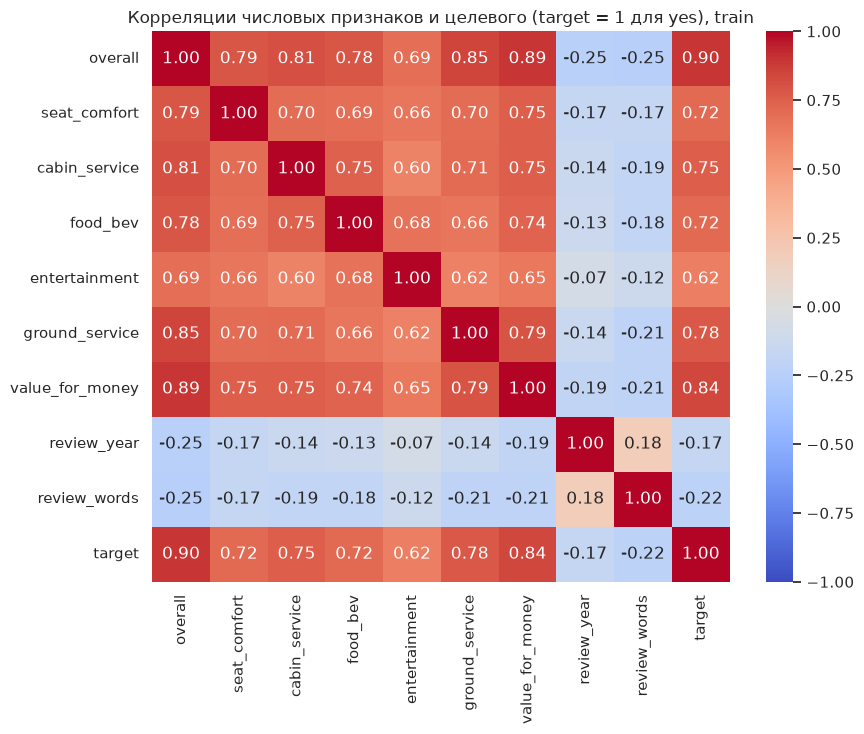

In [19]:
corr_cols = ['overall'] + rating_cols + ['review_year', 'review_words', 'target']
corr = train_df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Корреляции числовых признаков и целевого (target = 1 для yes), train')
plt.tight_layout()
plt.show()

- Оценки аспектов сильно коррелируют друг с другом (≈0.6–0.8) и с целевым признаком (≈0.6–0.85).
- Самая сильная связь с `target` у `overall` (≈0.9, та самая утечка) и у `value_for_money` (≈0.84).
- Год и длина отзыва связаны с целевым слабо и отрицательно (≈−0.2).
- Сильная взаимная корреляция оценок может мешать линейной модели и $k$NN (раздел 12).

## Итоги визуального анализа

- классы `recommended` почти сбалансированы;
- главные признаки — оценки аспектов, особенно `value_for_money`; они бимодальны и сильно коррелированы между собой;
- полезны также авиакомпания, класс обслуживания, тип путешественника и отметка верификации;
- у части признаков много пропусков (раздел 5).

# 4. Выбросы

In [20]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({'min': s.min(), 'max': s.max(), 'Q1': q1, 'Q3': q3,
                      'нижняя граница': low, 'верхняя граница': high,
                      'выбросов': ((s < low) | (s > high)).sum(),
                      'доля, %': round(((s < low) | (s > high)).mean() * 100, 2)})

X_train[rating_features + numeric_features + log_features].apply(lambda s: iqr_outliers(s.dropna())).T

,min,max,Q1,Q3,нижняя граница,верхняя граница,выбросов,"доля, %"
seat_comfort,1.0,5.0,2.0,4.0,-1.0,7.0,0.0,0.00
cabin_service,1.0,5.0,2.0,5.0,-2.5,9.5,0.0,0.00
food_bev,1.0,5.0,1.0,4.0,-3.5,8.5,0.0,0.00
entertainment,1.0,5.0,1.0,4.0,-3.5,8.5,0.0,0.00
ground_service,1.0,5.0,1.0,4.0,-3.5,8.5,0.0,0.00
value_for_money,1.0,5.0,1.0,4.0,-3.5,8.5,0.0,0.00
review_year,2002.0,2019.0,2014.0,2017.0,2009.5,2021.5,167.0,0.35
review_words,12.0,1003.0,74.0,173.0,-74.5,321.5,2457.0,5.14


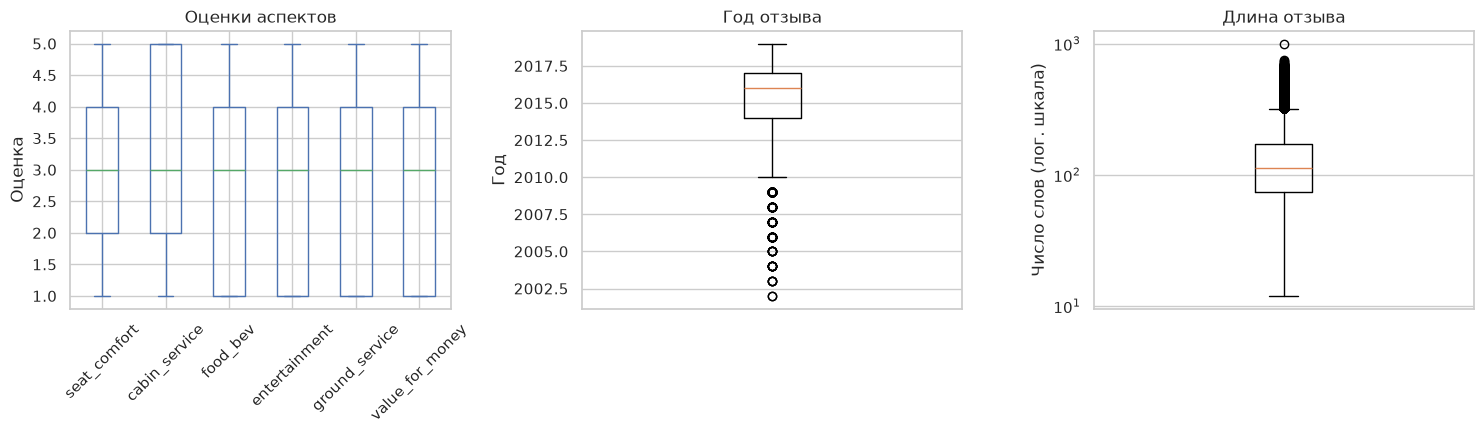

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
X_train[rating_features].plot.box(ax=axes[0], rot=45)
axes[0].set_title('Оценки аспектов')
axes[0].set_ylabel('Оценка')
axes[1].boxplot(X_train['review_year'].dropna())
axes[1].set_title('Год отзыва')
axes[1].set_ylabel('Год')
axes[1].set_xticks([])
axes[2].boxplot(X_train['review_words'])
axes[2].set_yscale('log')
axes[2].set_title('Длина отзыва')
axes[2].set_ylabel('Число слов (лог. шкала)')
axes[2].set_xticks([])
plt.tight_layout()
plt.show()

Правило IQR проверяет каждый числовой признак по отдельности и предполагает примерно симметричное унимодальное распределение. Для дискретных бимодальных оценок оно почти бесполезно. То, что IQR не нашёл выбросов среди оценок, означает лишь, что все значения лежат в пределах шкалы 1–5 (это проверено и в разделе 1). Поэтому дополнительно проверим **противоречивые отзывы**: все оценки высокие, но авиакомпанию не рекомендуют, или наоборот.

In [22]:
mean_rating = train_df[rating_cols].mean(axis=1)
n_rated = train_df[rating_cols].notna().sum(axis=1)
high_but_no = (mean_rating >= 4.5) & (n_rated >= 3) & (train_df['target'] == 0)
low_but_yes = (mean_rating <= 1.5) & (n_rated >= 3) & (train_df['target'] == 1)
print('Средняя оценка >= 4.5, но recommended = no :', high_but_no.sum())
print('Средняя оценка <= 1.5, но recommended = yes:', low_but_yes.sum())
print('Доля противоречивых отзывов в train: %.2f%%' % ((high_but_no | low_but_yes).mean() * 100))
train_df.loc[high_but_no | low_but_yes, ['airline', 'overall'] + rating_cols + ['recommended']].head()

Средняя оценка >= 4.5, но recommended = no : 26
Средняя оценка <= 1.5, но recommended = yes: 21
Доля противоречивых отзывов в train: 0.10%


,airline,overall,seat_comfort,cabin_service,food_bev,entertainment,ground_service,value_for_money,recommended
45457,Cathay Pacific Airways,6.0,5.0,5.0,4.0,3.0,5.0,5.0,no
40333,Singapore Airlines,10.0,4.0,5.0,5.0,5.0,NaN,5.0,no
8309,American Airlines,2.0,2.0,1.0,1.0,NaN,1.0,1.0,yes
7991,American Airlines,1.0,1.0,2.0,1.0,2.0,1.0,1.0,yes
44963,Air China,4.0,2.0,1.0,1.0,NaN,1.0,2.0,yes


Решения:
- **Оценки**: все значения допустимы, удалять нечего. Противоречивые отзывы составляют доли процента. Это, вероятно, ошибки заполнения анкеты или особые случаи (пассажир доволен полётом, но недоволен, например, возвратом билета). Удалять их не будем: в тестовой выборке такие отзывы тоже встречаются, и честная оценка качества должна их учитывать.
- **Год отзыва**: правило IQR помечает отзывы до ~2010 года. Это не ошибки, а просто редкие ранние отзывы, их оставляем.
- **Длина отзыва**: длинный правый хвост, IQR помечает ~5% отзывов. Это реальные развёрнутые отзывы, поэтому строки не удаляем, а **логарифмируем** признак (`log1p` внутри `Pipeline`). Так большие значения меньше влияют на расстояния в $k$NN и на линейную модель.

# 5. Пропущенные значения

In [23]:
missing = pd.DataFrame({'пропусков': train_df.isna().sum(),
                        'доля, %': (train_df.isna().mean() * 100).round(1)})
missing = missing[missing['пропусков'] > 0].sort_values('пропусков', ascending=False)
missing

,пропусков,"доля, %"
aircraft,33019,69.1
ground_service,18084,37.8
date_flown,17880,37.4
route,17809,37.3
traveller_type,17789,37.2
entertainment,15637,32.7
food_bev,9138,19.1
seat_comfort,2887,6.0
cabin_service,2857,6.0
overall,1379,2.9


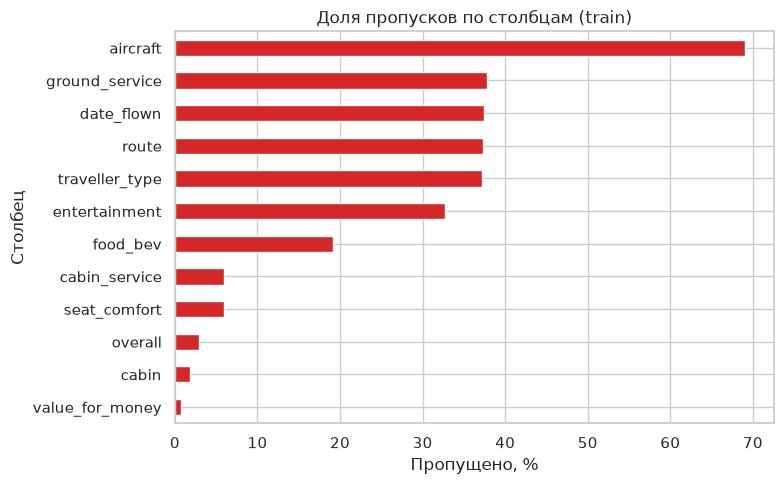

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))
missing['доля, %'].sort_values().plot.barh(ax=ax, color='tab:red')
ax.set_title('Доля пропусков по столбцам (train)')
ax.set_xlabel('Пропущено, %')
ax.set_ylabel('Столбец')
plt.tight_layout()
plt.show()

Пропусков много: у `aircraft` около 70%, у `ground_service`, `traveller_type`, `route`, `date_flown` около 40%, у `entertainment` около трети. Поля `traveller_type`, `route`, `date_flown`, `ground_service` и `aircraft` появились в анкете Skytrax позже (примерно в 2014 году), поэтому в старых отзывах их нет совсем. Пропуск в `entertainment` часто означает, что развлечений на борту просто нет (лоукостеры, короткие рейсы).

Проверим, связан ли сам факт пропуска с целевым признаком:

In [25]:
share_yes = {}
for col in rating_cols + ['traveller_type', 'cabin']:
    share_yes[col] = train_df.groupby(train_df[col].isna())['target'].mean()
share_yes = pd.DataFrame(share_yes).T.rename(columns={False: 'значение есть', True: 'пропуск'})
share_yes.round(3)

,значение есть,пропуск
seat_comfort,0.481,0.404
cabin_service,0.481,0.406
food_bev,0.519,0.300
entertainment,0.508,0.412
ground_service,0.428,0.557
value_for_money,0.480,0.085
traveller_type,0.426,0.562
cabin,0.481,0.267


Факт пропуска информативен. Например, если пассажир не оценил `value_for_money`, он рекомендует авиакомпанию лишь в ~8.5% случаев (против ~48% в среднем); без оценки `food_bev` — в ~30%. Вероятно, это отзывы-жалобы, где оценки заполнены частично. Значит, при заполнении пропусков нужно сохранить информацию о самом пропуске.

Стратегия (реализуется в `ColumnTransformer` в разделе 7, статистики считаются только по `X_train`):
- **оценки аспектов** — заполняем медианой обучающей выборки и добавляем бинарные индикаторы пропуска (`add_indicator=True`). Заполнение медианой не «выдумывает» оценку: модель видит индикатор и знает, что значение было пропущено;
- **год и длина отзыва** — пропусков нет, но на случай новых данных стоит импутация медианой;
- **категориальные признаки** (`traveller_type`, `cabin`) — пропуск становится отдельной категорией `'unknown'`, потому что он обозначает старую версию анкеты.

# 6. Обработка категориальных признаков

In [26]:
X_train[categorical_features].nunique().rename('уникальных значений в train').to_frame()

,уникальных значений в train
airline,81
cabin,4
traveller_type,4
verified,3
route_type,3


- Все категориальные признаки номинальные (порядка нет), поэтому кодируем их **one-hot** (`OneHotEncoder`), а не порядковыми номерами.
- У `airline` 81 значение. Категории, которые встречаются в обучающей выборке реже 30 раз, объединяются в одну «редкую» (`min_frequency=30`). Категории, которых не было в обучающей выборке, при предсказании не ломают модель (`handle_unknown='infrequent_if_exist'`).
- Высококардинальные поля (`route` — 24 тыс. значений, `aircraft` — 2 тыс., `author` — 44 тыс.) исключены: они почти уникальны, дают тысячи разреженных столбцов, и модель на них переобучилась бы.

# 7. Нормализация

Признаки имеют разные шкалы: оценки 1–5, год ~2002–2019, логарифм длины отзыва ~2.5–7, one-hot 0/1. Для **$k$NN нормализация обязательна**: иначе расстояние определялось бы в основном годом. Для логистической регрессии она нужна, чтобы регуляризация одинаково штрафовала веса. Деревьям масштаб не важен, но и не мешает. Используем `StandardScaler` (вычитание среднего и деление на стандартное отклонение обучающей выборки).

Полная предобработка собрана в один `ColumnTransformer`. Внутри `Pipeline` он обучается только на тех данных, на которых обучается модель, в том числе на обучающих фолдах кросс-валидации.

In [27]:
def make_preprocessor(ratings=rating_features, numeric=numeric_features,
                      log_numeric=log_features, categorical=categorical_features):
    transformers = []
    if ratings:
        transformers.append(('ratings', Pipeline([
            ('impute', SimpleImputer(strategy='median', add_indicator=True)),
            ('scale', StandardScaler())]), ratings))
    if numeric:
        transformers.append(('numeric', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler())]), numeric))
    if log_numeric:
        transformers.append(('log_numeric', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
            ('scale', StandardScaler())]), log_numeric))
    if categorical:
        transformers.append(('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value='unknown')),
            ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30,
                                     sparse_output=False))]), categorical))
    return ColumnTransformer(transformers)


preprocessor = make_preprocessor()
Xt_train = preprocessor.fit_transform(X_train)   # обучаем только на train
print('Размерность после преобразований:', Xt_train.shape)
display(pd.Series(preprocessor.get_feature_names_out()).str.split('__').str[0].value_counts())

# Проверка: после стандартизации у количественных признаков на train среднее ~0, std ~1
scaled = pd.DataFrame(Xt_train, columns=preprocessor.get_feature_names_out())
scaled[[c for c in scaled.columns if not c.startswith('categorical')]].describe().loc[['mean', 'std']].round(3)

Размерность после преобразований: (47804, 111)


categorical    97
ratings        12
numeric         1
log_numeric     1
Name: count, dtype: int64

,ratings__seat_comfort,ratings__cabin_service,ratings__food_bev,ratings__entertainment,ratings__ground_service,ratings__value_for_money,ratings__missingindicator_seat_comfort,ratings__missingindicator_cabin_service,ratings__missingindicator_food_bev,ratings__missingindicator_entertainment,ratings__missingindicator_ground_service,ratings__missingindicator_value_for_money,numeric__review_year,log_numeric__review_words
mean,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


После преобразований получается около ста признаков: 6 оценок и 6 индикаторов пропусков, 2 количественных и one-hot категории (в основном авиакомпании).

# 8. Классификатор $k$NN

**Почему $k$NN.** Это базовый метод курса, и он хорошо подходит к данным: основные признаки — оценки по одной шкале 1–5. Естественно ожидать, что отзывы с похожими оценками похожи и по итоговому решению. Метод не предполагает линейной зависимости и почти не требует настройки, кроме числа соседей $k$ и нормализации (раздел 7).

Начнём с $k = 5$ (значение по умолчанию).

In [28]:
def evaluate(model, name, X_tr=X_train, y_tr=y_train, X_te=X_test, y_te=y_test):
    # Метрики на обучающей и тестовой выборках
    rows = {}
    for part, Xp, yp in [('train', X_tr, y_tr), ('test', X_te, y_te)]:
        pred = model.predict(Xp)
        proba = model.predict_proba(Xp)[:, 1]
        rows[part] = {'accuracy': accuracy_score(yp, pred),
                      'error': 1 - accuracy_score(yp, pred),
                      'balanced acc.': balanced_accuracy_score(yp, pred),
                      'precision': precision_score(yp, pred, zero_division=0),
                      'recall': recall_score(yp, pred),
                      'F1': f1_score(yp, pred),
                      'ROC-AUC': roc_auc_score(yp, proba)}
    res = pd.DataFrame(rows).T
    res.index = pd.MultiIndex.from_product([[name], res.index])
    return res


results = []   # сюда собираем метрики всех моделей
models = {}    # и сами обученные модели

In [29]:
knn5 = Pipeline([('prep', make_preprocessor()),
                 ('clf', KNeighborsClassifier(n_neighbors=5, n_jobs=-1))])
knn5.fit(X_train, y_train)
res = evaluate(knn5, 'kNN (k = 5)')
results.append(res); models['kNN (k = 5)'] = knn5
res.round(4)

accuracy   error  balanced acc.  precision  recall      F1  ROC-AUC
kNN (k = 5) train    0.9513  0.0487         0.9514     0.9449  0.9535  0.9492   0.9923
            test     0.9327  0.0673         0.9326     0.9285  0.9305  0.9295   0.9727

# 9. Ошибки на обучающей и тестовой выборках, подбор $k$

Для $k = 5$ ошибка на обучающей выборке меньше, чем на тестовой: при малом $k$ модель частично «запоминает» обучающие объекты (каждый объект — сам себе ближайший сосед).

## Подбор числа соседей

**Критерий выбран заранее — F1-мера** для класса `yes`. Она учитывает и точность (precision), и полноту (recall). Классы почти сбалансированы, поэтому F1 и доля правильных ответов ведут себя похоже, но F1 не позволяет модели «отыграться» за счёт одного класса. Подбор выполняется 5-кратной стратифицированной кросс-валидацией **только на обучающей выборке**. Предобработка находится внутри `Pipeline` и переобучается на каждом фолде. Проверяем нечётные $k$ от 3 до 31 и для контроля несколько больших значений (41–101).

k,3,5,7,9,11,13,15,17,19,21,23,25,27,29,31,41,51,75,101
F1 (обучающие фолды),0.9552,0.9486,0.9455,0.9436,0.9422,0.9413,0.9410,0.9406,0.9405,0.9400,0.9397,0.9394,0.9391,0.9388,0.9386,0.9379,0.9373,0.9364,0.9356
F1 (валидация),0.9262,0.9315,0.9333,0.9343,0.9350,0.9352,0.9361,0.9361,0.9360,0.9360,0.9355,0.9355,0.9357,0.9354,0.9354,0.9354,0.9358,0.9357,0.9349
std,0.0014,0.0010,0.0014,0.0012,0.0004,0.0010,0.0013,0.0015,0.0018,0.0016,0.0018,0.0018,0.0023,0.0025,0.0022,0.0018,0.0021,0.0025,0.0025


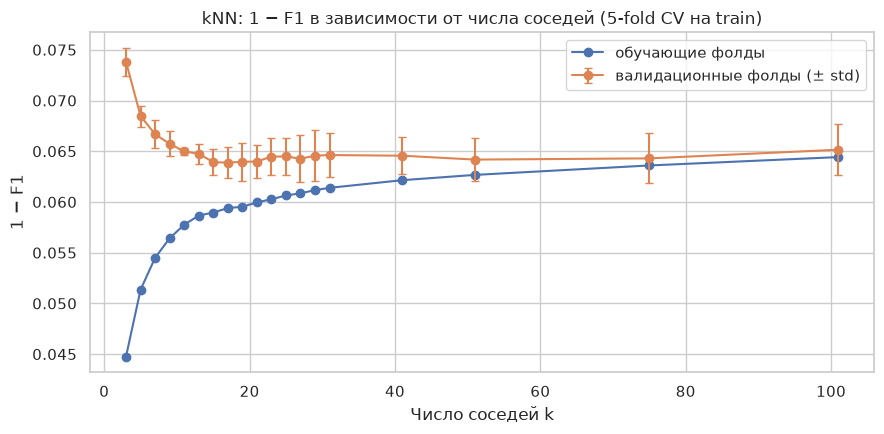

Оптимальное k: 17  (критерий — средняя F1 на валидации = 0.9361)


In [30]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
k_values = list(range(3, 32, 2)) + [41, 51, 75, 101]
knn_grid = GridSearchCV(
    Pipeline([('prep', make_preprocessor()), ('clf', KNeighborsClassifier())]),
    {'clf__n_neighbors': k_values},
    cv=cv, scoring='f1', return_train_score=True, n_jobs=-1)
knn_grid.fit(X_train, y_train)

cv_res = pd.DataFrame(knn_grid.cv_results_)
display(cv_res[['param_clf__n_neighbors', 'mean_train_score', 'mean_test_score', 'std_test_score']]
        .rename(columns={'param_clf__n_neighbors': 'k', 'mean_train_score': 'F1 (обучающие фолды)',
                         'mean_test_score': 'F1 (валидация)', 'std_test_score': 'std'})
        .set_index('k').T.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(cv_res['param_clf__n_neighbors'], 1 - cv_res['mean_train_score'], marker='o', label='обучающие фолды')
ax.errorbar(cv_res['param_clf__n_neighbors'], 1 - cv_res['mean_test_score'], yerr=cv_res['std_test_score'],
            marker='o', capsize=3, label='валидационные фолды (± std)')
ax.set_title('kNN: 1 − F1 в зависимости от числа соседей (5-fold CV на train)')
ax.set_xlabel('Число соседей k')
ax.set_ylabel('1 − F1')
ax.legend()
plt.tight_layout()
plt.show()

best_k = knn_grid.best_params_['clf__n_neighbors']
print('Оптимальное k:', best_k, ' (критерий — средняя F1 на валидации = %.4f)' % knn_grid.best_score_)

In [31]:
knn_best = knn_grid.best_estimator_   # переобучен на всей обучающей выборке с лучшим k
name = f'kNN (k = {best_k})'
res = evaluate(knn_best, name)
results.append(res); models[name] = knn_best
pd.concat(results).round(4)

accuracy   error  balanced acc.  precision  recall      F1  ROC-AUC
kNN (k = 5)  train    0.9513  0.0487         0.9514     0.9449  0.9535  0.9492   0.9923
             test     0.9327  0.0673         0.9326     0.9285  0.9305  0.9295   0.9727
kNN (k = 17) train    0.9432  0.0568         0.9434     0.9355  0.9462  0.9408   0.9889
             test     0.9382  0.0618         0.9383     0.9308  0.9402  0.9355   0.9812

- При $k = 3$ F1 на обучающих фолдах (~0.955) заметно выше, чем на валидации (~0.926): модель переобучается, ориентируясь на 1–2 ближайших отзыва.
- С ростом $k$ кривые сближаются. Начиная с $k pprox 15$ валидационная F1 выходит на плато (~0.935–0.936), разница между соседними $k$ меньше стандартного отклонения по фолдам.
- При $k = 101$ качество на валидации немного падает: модель становится слишком «гладкой» (начало недообучения).
- Формально лучшее значение по критерию F1 — то, что напечатано выше. Для него разрыв между train и test около 0.5 п. п. по accuracy, то есть модель не переобучена.

## Матрицы рассогласования

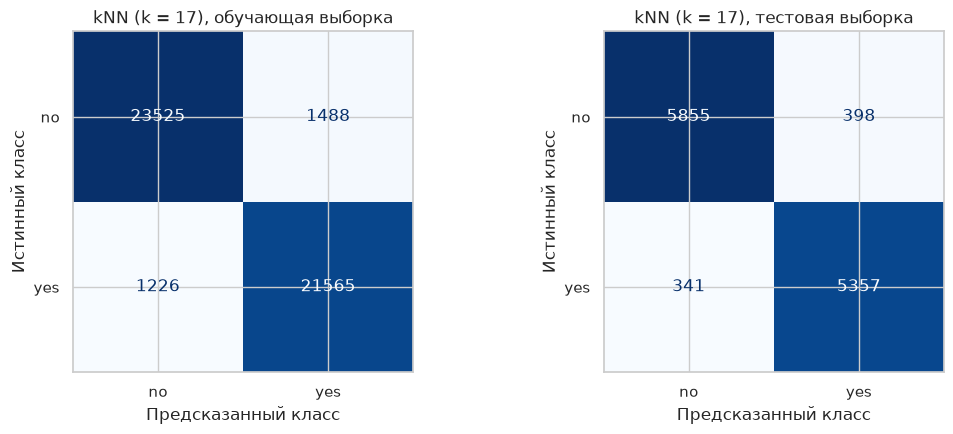

train: TN=23525, FP=1488, FN=1226, TP=21565;  доля FP среди no = 0.059, доля FN среди yes = 0.054


test: TN=5855, FP=398, FN=341, TP=5357;  доля FP среди no = 0.064, доля FN среди yes = 0.060



              precision    recall  f1-score   support

          no      0.945     0.936     0.941      6253
         yes      0.931     0.940     0.935      5698

    accuracy                          0.938     11951
   macro avg      0.938     0.938     0.938     11951
weighted avg      0.938     0.938     0.938     11951



In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (part, Xp, yp) in zip(axes, [('обучающая', X_train, y_train), ('тестовая', X_test, y_test)]):
    ConfusionMatrixDisplay.from_estimator(knn_best, Xp, yp, display_labels=['no', 'yes'],
                                          cmap='Blues', values_format='d', ax=ax, colorbar=False)
    ax.set_title(f'kNN (k = {best_k}), {part} выборка')
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()

for part, Xp, yp in [('train', X_train, y_train), ('test', X_test, y_test)]:
    tn, fp, fn, tp = confusion_matrix(yp, knn_best.predict(Xp)).ravel()
    print(f'{part}: TN={tn}, FP={fp}, FN={fn}, TP={tp};  '
          f'доля FP среди no = {fp / (fp + tn):.3f}, доля FN среди yes = {fn / (fn + tp):.3f}')
print()
print(classification_report(y_test, knn_best.predict(X_test), target_names=['no', 'yes'], digits=3))

**Интерпретация ошибок.**
- *Ложноположительные (FP)*: модель говорит «рекомендует», а пассажир не рекомендует. Обычно это отзывы со средними или смешанными оценками (например, кресло и сервис хорошие, а цена/качество плохое) или противоречивые отзывы из раздела 4.
- *Ложноотрицательные (FN)*: пассажир рекомендует, хотя оценки у него средние или часть оценок пропущена.
- Ошибок обоих типов примерно поровну, явного перекоса в сторону одного класса нет. Это ожидаемо при почти сбалансированных классах.
- Доли ошибок на train и test близки, поэтому серьёзного переобучения нет. Ошибки сосредоточены в «пограничной» зоне, где оценки не дают однозначного ответа.

# 10. Другие классификаторы

Для сравнения обучим:
- **DummyClassifier** — всегда предсказывает самый частый класс (нижняя граница качества);
- **логистическую регрессию** — подбираем коэффициент регуляризации $C$;
- **решающее дерево** — подбираем глубину и минимальный размер листа;
- **случайный лес** (Random Forest);
- **градиентный бустинг** (`HistGradientBoostingClassifier`).

Гиперпараметры подбираются той же кросс-валидацией на обучающей выборке и по тому же критерию (F1). `SVC` с ядром не берём: на ~48 тысячах объектов его обучение занимает слишком много времени, а линейный классификатор уже представлен логистической регрессией.

In [33]:
dummy = Pipeline([('prep', make_preprocessor()),
                  ('clf', DummyClassifier(strategy='most_frequent'))]).fit(X_train, y_train)
res = evaluate(dummy, 'Dummy (most frequent)')
results.append(res); models['Dummy (most frequent)'] = dummy
res.round(4)

accuracy   error  balanced acc.  precision  recall   F1  ROC-AUC
Dummy (most frequent) train    0.5232  0.4768            0.5        0.0     0.0  0.0      0.5
                      test     0.5232  0.4768            0.5        0.0     0.0  0.0      0.5

## Логистическая регрессия

In [34]:
logreg_grid = GridSearchCV(
    Pipeline([('prep', make_preprocessor()),
              ('clf', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))]),
    {'clf__C': [0.001, 0.01, 0.1, 1, 10]}, cv=cv, scoring='f1', n_jobs=-1)
logreg_grid.fit(X_train, y_train)
print('Лучшее C:', logreg_grid.best_params_['clf__C'], ' CV F1 = %.4f' % logreg_grid.best_score_)

logreg = logreg_grid.best_estimator_
res = evaluate(logreg, 'Логистическая регрессия')
results.append(res); models['Логистическая регрессия'] = logreg
res.round(4)

Лучшее C: 10  CV F1 = 0.9380


accuracy   error  balanced acc.  precision  recall      F1  ROC-AUC
Логистическая регрессия train    0.9411  0.0589         0.9411     0.9355  0.9415  0.9385   0.9855
                        test     0.9419  0.0581         0.9419     0.9379  0.9405  0.9392   0.9849

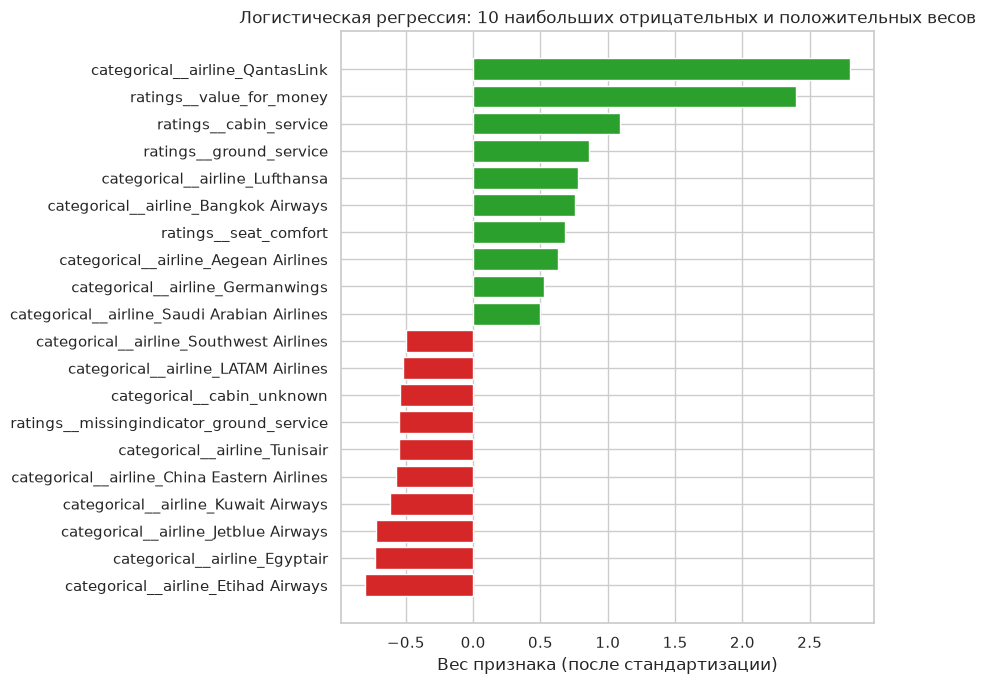

In [35]:
coef = pd.Series(logreg.named_steps['clf'].coef_[0],
                 index=logreg.named_steps['prep'].get_feature_names_out())
top_coef = pd.concat([coef.sort_values().head(10), coef.sort_values().tail(10)])
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_coef.index, top_coef.values,
        color=['tab:red' if v < 0 else 'tab:green' for v in top_coef.values])
ax.set_title('Логистическая регрессия: 10 наибольших отрицательных и положительных весов')
ax.set_xlabel('Вес признака (после стандартизации)')
plt.tight_layout()
plt.show()

## Решающее дерево

In [36]:
tree_grid = GridSearchCV(
    Pipeline([('prep', make_preprocessor()),
              ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    {'clf__max_depth': [3, 5, 8, 12, None], 'clf__min_samples_leaf': [1, 20, 100]},
    cv=cv, scoring='f1', n_jobs=-1)
tree_grid.fit(X_train, y_train)
print('Лучшие параметры:', tree_grid.best_params_, ' CV F1 = %.4f' % tree_grid.best_score_)

tree = tree_grid.best_estimator_
res = evaluate(tree, 'Решающее дерево')
results.append(res); models['Решающее дерево'] = tree
res.round(4)

Лучшие параметры: {'clf__max_depth': 8, 'clf__min_samples_leaf': 20}  CV F1 = 0.9336


accuracy   error  balanced acc.  precision  recall      F1  ROC-AUC
Решающее дерево train    0.9417  0.0583         0.9413      0.944  0.9330  0.9385   0.9851
                test     0.9373  0.0627         0.9368      0.942  0.9256  0.9337   0.9818

## Случайный лес (Random Forest)

In [37]:
forest = Pipeline([('prep', make_preprocessor()),
                   ('clf', RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                  n_jobs=-1, random_state=RANDOM_STATE))])
forest.fit(X_train, y_train)
res = evaluate(forest, 'Random Forest')
results.append(res); models['Random Forest'] = forest
res.round(4)

accuracy   error  balanced acc.  precision  recall      F1  ROC-AUC
Random Forest train    0.9558  0.0442         0.9555      0.957  0.9500  0.9535   0.9934
              test     0.9409  0.0591         0.9405      0.943  0.9324  0.9377   0.9859

## Градиентный бустинг

In [38]:
boosting = Pipeline([('prep', make_preprocessor()),
                     ('clf', HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1,
                                                            random_state=RANDOM_STATE))])
boosting.fit(X_train, y_train)
res = evaluate(boosting, 'Gradient Boosting (HGB)')
results.append(res); models['Gradient Boosting (HGB)'] = boosting
res.round(4)

accuracy   error  balanced acc.  precision  recall      F1  ROC-AUC
Gradient Boosting (HGB) train    0.9491  0.0509         0.9491     0.9457  0.9478  0.9467   0.9905
                        test     0.9423  0.0577         0.9420     0.9427  0.9358  0.9392   0.9859

## Сравнение моделей

**Выбор лучшей модели — только по кросс-валидации на обучающей выборке.** Тестовые метрики служат итоговой оценкой и в выборе не участвуют. Для каждой модели (с уже подобранными гиперпараметрами) считаем несколько метрик на тех же 5 фолдах. У моделей, чьи параметры подбирались на этих фолдах, оценка немного оптимистична, но одинаково для всех.

In [39]:
scoring = {'accuracy': 'accuracy', 'balanced acc.': 'balanced_accuracy', 'F1': 'f1', 'ROC-AUC': 'roc_auc'}
cv_rows = {}
for name, model in models.items():
    scores = cross_validate(clone(model), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows[name] = {m: scores[f'test_{m}'].mean() for m in scoring}
    cv_rows[name]['F1 std'] = scores['test_F1'].std()
cv_table = pd.DataFrame(cv_rows).T.sort_values('F1', ascending=False)
cv_table.round(4)

,accuracy,balanced acc.,F1,ROC-AUC,F1 std
Gradient Boosting (HGB),0.9419,0.9417,0.9390,0.9860,0.0012
Random Forest,0.9413,0.9410,0.9382,0.9856,0.0020
Логистическая регрессия,0.9407,0.9407,0.9380,0.9851,0.0023
kNN (k = 17),0.9387,0.9389,0.9361,0.9819,0.0015
Решающее дерево,0.9369,0.9366,0.9336,0.9818,0.0010
kNN (k = 5),0.9343,0.9344,0.9315,0.9715,0.0010
Dummy (most frequent),0.5232,0.5000,0.0000,0.5000,0.0000


In [40]:
best_name = cv_table.index[0]
best_model = models[best_name]
print('Лучшая модель по CV F1 на обучающей выборке:', best_name)

all_results = pd.concat(results)
test_results = all_results.xs('test', level=1).loc[cv_table.index]
train_results = all_results.xs('train', level=1).loc[cv_table.index]
comparison = test_results.copy()
comparison.insert(0, 'CV F1 (train)', cv_table['F1'])
comparison['accuracy (train)'] = train_results['accuracy']
print('Итоговые метрики на тестовой выборке (порядок — по CV F1):')
comparison.round(4)

Лучшая модель по CV F1 на обучающей выборке: Gradient Boosting (HGB)
Итоговые метрики на тестовой выборке (порядок — по CV F1):


,CV F1 (train),accuracy,error,balanced acc.,precision,recall,F1,ROC-AUC,accuracy (train)
Gradient Boosting (HGB),0.9390,0.9423,0.0577,0.9420,0.9427,0.9358,0.9392,0.9859,0.9491
Random Forest,0.9382,0.9409,0.0591,0.9405,0.9430,0.9324,0.9377,0.9859,0.9558
Логистическая регрессия,0.9380,0.9419,0.0581,0.9419,0.9379,0.9405,0.9392,0.9849,0.9411
kNN (k = 17),0.9361,0.9382,0.0618,0.9383,0.9308,0.9402,0.9355,0.9812,0.9432
Решающее дерево,0.9336,0.9373,0.0627,0.9368,0.9420,0.9256,0.9337,0.9818,0.9417
kNN (k = 5),0.9315,0.9327,0.0673,0.9326,0.9285,0.9305,0.9295,0.9727,0.9513
Dummy (most frequent),0.0000,0.5232,0.4768,0.5000,0.0000,0.0000,0.0000,0.5000,0.5232


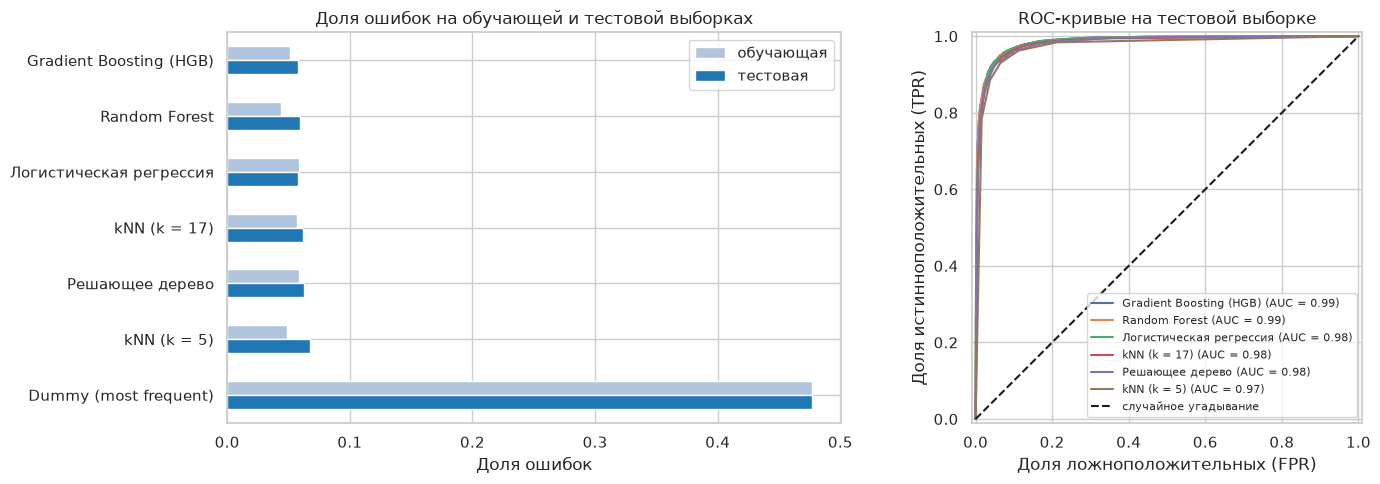

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = cv_table.index
plot_df = pd.DataFrame({'обучающая': train_results.loc[order, 'error'],
                        'тестовая': test_results.loc[order, 'error']})
plot_df.plot.barh(ax=axes[0], color=['lightsteelblue', 'tab:blue'])
axes[0].set_title('Доля ошибок на обучающей и тестовой выборках')
axes[0].set_xlabel('Доля ошибок')
axes[0].set_ylabel('')
axes[0].invert_yaxis()

real_models = [m for m in order if not m.startswith('Dummy')]
for m in real_models:
    RocCurveDisplay.from_estimator(models[m], X_test, y_test, name=m, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', label='случайное угадывание')
axes[1].set_title('ROC-кривые на тестовой выборке')
axes[1].set_xlabel('Доля ложноположительных (FPR)')
axes[1].set_ylabel('Доля истинноположительных (TPR)')
axes[1].legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

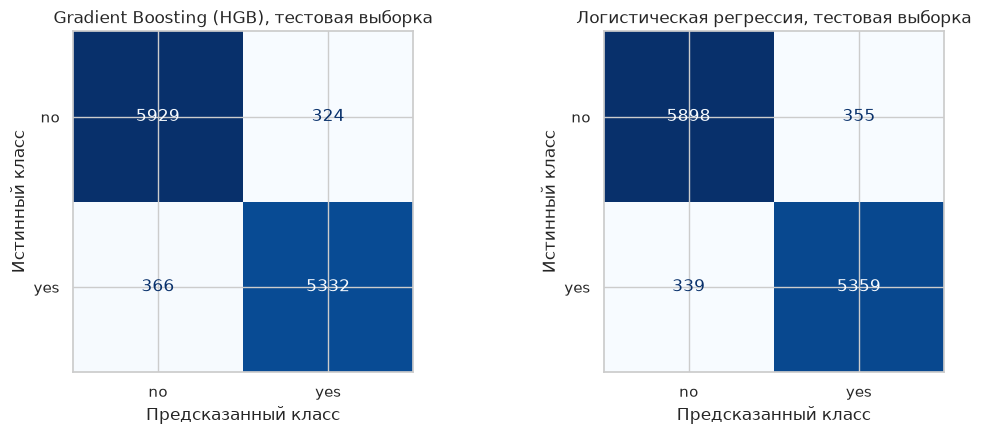

              precision    recall  f1-score   support

          no      0.942     0.948     0.945      6253
         yes      0.943     0.936     0.939      5698

    accuracy                          0.942     11951
   macro avg      0.942     0.942     0.942     11951
weighted avg      0.942     0.942     0.942     11951



In [42]:
other_name = 'Логистическая регрессия' if best_name != 'Логистическая регрессия' else 'Random Forest'
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, m in zip(axes, [best_name, other_name]):
    ConfusionMatrixDisplay.from_estimator(models[m], X_test, y_test, display_labels=['no', 'yes'],
                                          cmap='Blues', values_format='d', ax=ax, colorbar=False)
    ax.set_title(f'{m}, тестовая выборка')
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()

print(classification_report(y_test, best_model.predict(X_test), target_names=['no', 'yes'], digits=3))

## Значимость признаков

Оценим важность исходных признаков для выбранной модели методом перестановок (permutation importance): насколько падает ROC-AUC, если случайно перемешать значения одного признака. Это интерпретация уже выбранной модели, а не выбор модели, поэтому считаем на тестовой выборке.

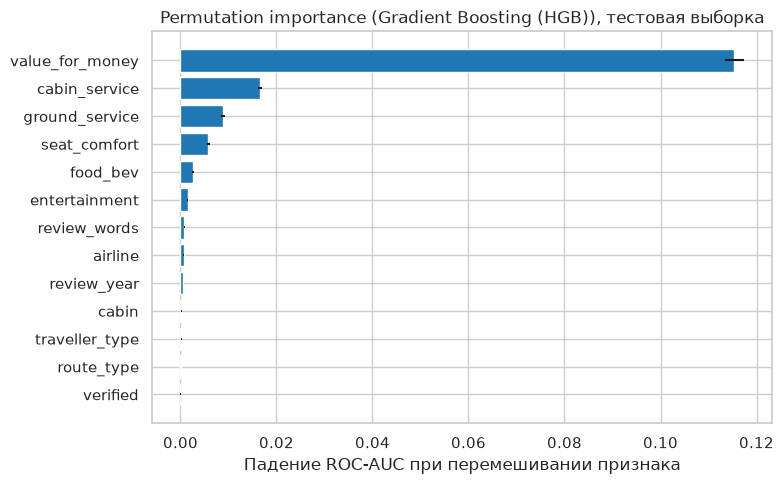

,mean,std
value_for_money,0.1154,0.0020
cabin_service,0.0166,0.0004
ground_service,0.0088,0.0004
seat_comfort,0.0058,0.0003
food_bev,0.0027,0.0002
entertainment,0.0015,0.0001
review_words,0.0008,0.0001
airline,0.0006,0.0000
review_year,0.0005,0.0001
cabin,0.0002,0.0001


In [43]:
perm = permutation_importance(best_model, X_test, y_test, scoring='roc_auc',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance = pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std},
                          index=X_test.columns).sort_values('mean')

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance['mean'], xerr=importance['std'], color='tab:blue')
ax.set_title(f'Permutation importance ({best_name}), тестовая выборка')
ax.set_xlabel('Падение ROC-AUC при перемешивании признака')
plt.tight_layout()
plt.show()
importance.sort_values('mean', ascending=False).round(4)

## Дополнительный сценарий: без оценок аспектов

Оценки аспектов пассажир ставит в том же отзыве, что и рекомендацию. Проверим, насколько хорошо можно предсказать рекомендацию **только по сведениям, известным до полёта**: авиакомпания, класс обслуживания, тип путешественника, тип маршрута, год. Отметку верификации и длину текста здесь тоже не используем, они появляются только вместе с отзывом.

In [44]:
pre_flight_cat = ['airline', 'cabin', 'traveller_type', 'route_type']
pre_flight_num = ['review_year']
pre_cols = pre_flight_cat + pre_flight_num
pre_results = []
for name, clf in [('Dummy (most frequent)', DummyClassifier(strategy='most_frequent')),
                  ('Логистическая регрессия', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
                  ('Gradient Boosting (HGB)', HistGradientBoostingClassifier(max_iter=300,
                                                                             random_state=RANDOM_STATE))]:
    m = Pipeline([('prep', make_preprocessor(ratings=[], numeric=pre_flight_num, log_numeric=[],
                                             categorical=pre_flight_cat)), ('clf', clf)])
    m.fit(X_train[pre_cols], y_train)
    pre_results.append(evaluate(m, name + ' (до полёта)', X_train[pre_cols], y_train,
                                X_test[pre_cols], y_test))
pd.concat(pre_results).round(4)

accuracy   error  balanced acc.  precision  recall      F1  ROC-AUC
Dummy (most frequent) (до полёта)   train    0.5232  0.4768         0.5000     0.0000  0.0000  0.0000   0.5000
                                    test     0.5232  0.4768         0.5000     0.0000  0.0000  0.0000   0.5000
Логистическая регрессия (до полёта) train    0.6895  0.3105         0.6874     0.6861  0.6428  0.6638   0.7581
                                    test     0.6938  0.3062         0.6915     0.6931  0.6422  0.6667   0.7594
Gradient Boosting (HGB) (до полёта) train    0.7085  0.2915         0.7081     0.6920  0.7000  0.6960   0.7822
                                    test     0.7015  0.2985         0.7008     0.6878  0.6848  0.6863   0.7739

# 11. Несбалансированность классов

Выраженного дисбаланса нет: в обучающей выборке около 52% `no` и 48% `yes`. Специальная обработка не обязательна. Для проверки сравним логистическую регрессию и случайный лес со взвешиванием классов (`class_weight='balanced'`) и без него.

In [45]:
balanced_results = []
for name in ['Логистическая регрессия', 'Random Forest']:
    model_bal = clone(models[name]).set_params(clf__class_weight='balanced')
    model_bal.fit(X_train, y_train)
    balanced_results.append(evaluate(model_bal, name + ' (balanced)').xs('test', level=1))
    balanced_results.append(test_results.loc[[name]])
pd.concat(balanced_results).round(4)

,accuracy,error,balanced acc.,precision,recall,F1,ROC-AUC
Логистическая регрессия (balanced),0.9409,0.0591,0.9410,0.9335,0.9433,0.9384,0.9849
Логистическая регрессия,0.9419,0.0581,0.9419,0.9379,0.9405,0.9392,0.9849
Random Forest (balanced),0.9423,0.0577,0.9421,0.9416,0.9372,0.9394,0.9858
Random Forest,0.9409,0.0591,0.9405,0.9430,0.9324,0.9377,0.9859


# 12. Исключение коррелированных признаков

**Зачем.** Сильно коррелированные признаки почти дублируют друг друга:
- в **$k$NN** такая информация учитывается в расстоянии дважды, и этот аспект «перевешивает» остальные;
- в **логистической регрессии** веса коррелированных признаков становятся неустойчивыми (мультиколлинеарность) и плохо интерпретируются;
- деревьям корреляция почти не мешает.

Порог 0.75 по модулю. Корреляции считаются **только на обучающей выборке**. Из каждой сильной пары жадно удаляем признак, у которого больше всего сильных связей.

In [46]:
CORR_THRESHOLD = 0.75
corr_train = X_train[rating_features].corr().abs()
upper = corr_train.where(np.triu(np.ones(corr_train.shape, dtype=bool), k=1))
pairs = upper.stack()
print('Пары с |r| >', CORR_THRESHOLD)
print(pairs[pairs > CORR_THRESHOLD].round(3))

to_drop = []
remaining = list(rating_features)
while True:
    c = X_train[remaining].corr().abs()
    c = c.mask(np.eye(len(c), dtype=bool), 0)   # обнуляем диагональ
    if (c > CORR_THRESHOLD).sum().sum() == 0:
        break
    worst = (c > CORR_THRESHOLD).sum().idxmax()
    to_drop.append(worst)
    remaining.remove(worst)
print('Удаляем:', to_drop)

Пары с |r| > 0.75
seat_comfort    value_for_money    0.751
cabin_service   value_for_money    0.751
ground_service  value_for_money    0.793
dtype: float64
Удаляем: ['value_for_money']


In [47]:
reduced_ratings = [c for c in rating_features if c not in to_drop]
reduced_cols = reduced_ratings + numeric_features + log_features + categorical_features
reduced_results = []
for name in [f'kNN (k = {best_k})', 'Логистическая регрессия', 'Random Forest']:
    m = clone(models[name]).set_params(prep=make_preprocessor(ratings=reduced_ratings))
    m.fit(X_train[reduced_cols], y_train)
    reduced_results.append(evaluate(m, name + ' (без коррелир.)', X_train[reduced_cols], y_train,
                                    X_test[reduced_cols], y_test).xs('test', level=1))
    reduced_results.append(test_results.loc[[name]])
pd.concat(reduced_results).round(4)

,accuracy,error,balanced acc.,precision,recall,F1,ROC-AUC
kNN (k = 17) (без коррелир.),0.9106,0.0894,0.9106,0.9019,0.9115,0.9067,0.9684
kNN (k = 17),0.9382,0.0618,0.9383,0.9308,0.9402,0.9355,0.9812
Логистическая регрессия (без коррелир.),0.9131,0.0869,0.9130,0.9070,0.9110,0.9090,0.9695
Логистическая регрессия,0.9419,0.0581,0.9419,0.9379,0.9405,0.9392,0.9849
Random Forest (без коррелир.),0.9145,0.0855,0.9141,0.9148,0.9049,0.9098,0.9728
Random Forest,0.9409,0.0591,0.9405,0.9430,0.9324,0.9377,0.9859


# 13. Выводы

### Что выяснили о данных

- В файле 131 895 строк, но 65 948 из них полностью пустые (каждая вторая строка). Ещё 4 770 строк — дубликаты, у 1 422 отзывов нет ответа о рекомендации. Осталось **59 755 отзывов** о 81 авиакомпании за 2002–2019 годы: 47 804 в обучающей и 11 951 в тестовой выборке.
- Классы почти сбалансированы: 52.3% `no` и 47.7% `yes`.
- Пропусков много (`aircraft` ~69%, `ground_service`, `route`, `traveller_type`, `date_flown` ~37–38%, `entertainment` ~33%). В основном это поля, которых не было в старой версии анкеты. Сам факт пропуска связан с ответом: без оценки `value_for_money` рекомендуют лишь в 8.5% случаев.
- Общая оценка `overall` — почти тот же ответ, что и рекомендация: правило «`overall` ≥ 6 → yes» угадывает 95.4% ответов (корреляция ≈0.9). Поэтому `overall` исключён как утечка; текст отзыва тоже не используется.
- Оценки аспектов бимодальны (чаще всего 1 или 5), сильно коррелируют с рекомендацией (≈0.6–0.85) и между собой (≈0.6–0.8). У рекомендующих они в среднем на 1.9–2.7 балла выше.
- Доля рекомендаций сильно зависит от авиакомпании (от 0.14 у Frontier до 0.90 у Garuda Indonesia) и от класса обслуживания (бизнес/первый ~0.62–0.67, эконом ~0.44). Со временем она снижается: ~0.6–0.65 в 2010–2012 годах, ~0.31 в 2019.

### Подготовка данных

- до разбиения выполнялись только построчные технические операции: удаление пустых строк, дубликатов и отзывов без целевого признака; разбор даты, отметки верификации, длины текста и типа маршрута;
- разбиение 80/20 со стратификацией (`random_state = 42`); разведочный анализ, анализ выбросов и пропусков — на обучающей выборке;
- выбросов в смысле недопустимых значений нет: все оценки в пределах шкал. Правило IQR помечает ранние отзывы (0.35%) и длинные тексты (5.1%), но это реальные данные. Противоречивых отзывов (высокие оценки и «не рекомендую» или наоборот) всего 0.1%. Строки не удалялись, длина текста логарифмирована;
- пропуски в оценках заполняются медианой с индикаторами пропуска, в категориях пропуск стал отдельной категорией; one-hot кодирование; `StandardScaler`. Всё это находится в одном `ColumnTransformer` внутри `Pipeline` и обучается только на обучающих данных;
- исключены `overall` и текст (утечка), `author` (идентификатор), `aircraft`, `route`, `date_flown` (много пропусков или слишком высокая кардинальность).

### $k$NN

- $k$ подбирался 5-кратной кросс-валидацией на обучающей выборке по заранее выбранному критерию F1 среди $k$ = 3, 5, …, 31, 41, 51, 75, 101. Оптимум: **$k = 17$** (CV F1 = 0.936). Начиная с $k \approx 15$ кривая выходит на плато.
- При $k = 5$ модель немного переобучается: accuracy 0.951 на train против 0.933 на test.
- При $k = 17$ на train accuracy 0.943, на test 0.938 (ошибка 6.2%), F1 0.936, ROC-AUC 0.981. На тесте 398 ложноположительных и 341 ложноотрицательных ответов из 11 951, то есть ошибок обоих типов примерно поровну.

### Сравнение моделей

| Модель | CV F1 (train) | accuracy (test) | F1 (test) | ROC-AUC (test) | accuracy (train) |
|---|---|---|---|---|---|
| Gradient Boosting (HGB) | 0.939 | 0.942 | 0.939 | 0.986 | 0.949 |
| Random Forest | 0.938 | 0.941 | 0.938 | 0.986 | 0.956 |
| Логистическая регрессия ($C = 10$) | 0.938 | 0.942 | 0.939 | 0.985 | 0.941 |
| kNN ($k = 17$) | 0.936 | 0.938 | 0.936 | 0.981 | 0.943 |
| Решающее дерево (глубина 8) | 0.934 | 0.937 | 0.934 | 0.982 | 0.942 |
| kNN ($k = 5$) | 0.932 | 0.933 | 0.930 | 0.973 | 0.951 |
| Dummy (самый частый класс) | 0.000 | 0.523 | 0.000 | 0.500 | 0.523 |

- Лучшая модель выбиралась по кросс-валидации на обучающей выборке: это **градиентный бустинг** (CV F1 0.939). На тесте он даёт accuracy 0.942 (ошибка 5.8%), F1 0.939, ROC-AUC 0.986.
- Бустинг, случайный лес и логистическая регрессия различаются меньше чем на 0.001 по CV F1 (стандартное отклонение по фолдам 0.001–0.002), то есть **практически равны**. Логистическая регрессия проще и лучше интерпретируется, и у неё нет разрыва между train и test. Случайный лес немного переобучается (0.956 на train).
- Все модели в разы лучше константного ответа (ошибка ~6% против ~48%). Precision и recall сбалансированы, поэтому высокая accuracy здесь не обманчива.
- Важнее всего `value_for_money`; за ним идут `cabin_service`, `ground_service` и `seat_comfort`. При наличии оценок авиакомпания, класс, год и длина текста почти ничего не добавляют.
- **Без оценок** (только авиакомпания, класс, тип путешественника, маршрут, год) качество намного ниже: accuracy ~0.69–0.70, ROC-AUC ~0.76–0.77. Высокое качество основной модели получается за счёт оценок пассажира.

### Дополнительные эксперименты

- **Дисбаланс**: выраженного дисбаланса нет. `class_weight='balanced'` меняет метрики на тысячные доли (у леса немного растёт recall, у регрессии немного падает precision).
- **Коррелированные признаки**: при пороге 0.75 удаляется `value_for_money` (связан сразу с тремя оценками). Качество всех моделей падает с ~0.94 до ~0.91. Корреляция здесь не мешала, а удалённый признак самый информативный. Значит, удалять коррелированные признаки нужно с проверкой их ценности для целевой переменной.

### Ограничения

- Оценки аспектов и рекомендация заполняются одновременно, после полёта. Поэтому модель восстанавливает итоговое решение по оценкам, а **не прогнозирует рекомендацию до полёта**. Для прогноза «заранее» качество гораздо скромнее (accuracy ~0.70).
- Разбиение случайное, а не по времени. Доля рекомендаций со временем меняется, поэтому на новых отзывах качество может отличаться.
- Один автор может оставить несколько отзывов, и они могут попасть в обе выборки.
- Отзывы на Skytrax оставляют добровольно, поэтому выборка смещена к крайним мнениям.
